# Multiscale Mobile-Former ablation **E4_vit2_patch16** on Chest CT-Scan lung cancer (4-class)

Ablation study on the **Multiscale Mobile-Former (MMF)** hybrid from `Multiscale_MobileFormer_Chexpert.ipynb`: pretrained MobileNetV2 (first 50% frozen) -> decoder bus (14x14x64, 28x28x32, 56x56x16) -> two small ViTs, in parallel with a CNN head; the three feature vectors are concatenated -> BatchNorm1d -> classifier.

**Rules for every experiment (from your sir):** 2maxmin is **not** used (and the x-multiplier is not used either, since the features are fetched directly). Everything else is identical to the baseline model and training recipe. **Fusion widths are CNN : ViT-1 : ViT-2 = 128 : 48 : 48** (the CNN head is 128 wide, as in Fig. 1).

| Experiment | What changes |
|---|---|
| **E1** | the **14x14x64** decoder output is connected directly to ViT-1 (the 7x7-patch ViT) |
| **E2** | the **28x28x32** decoder output is connected directly to ViT-2 (the 8x8-patch ViT) |
| **E3** | ViT-1 uses **16x16** patches (replacing 7x7) |
| **E4** | ViT-2 uses **16x16** patches |
| **E5** | ViT-1 uses **16x16** patches and ViT-2 uses **7x7** patches (see assumption 3) |
| *E0 (optional)* | the original model with 2maxmin + x1.25, for reference |

Extra (section 7): images after **2maxmin followed by the x1.1 multiplier**, shown on the X-rays and on the 28x28x32 decoder features.

**Assumptions I made (all are plain numbers in the config cell, easy to change):**
1. ViT naming follows **Fig. 1 of the paper**: ViT-1 = 28x28x32 branch with 7x7 patches (the 2maxmin branch in the original model); ViT-2 = 56x56x16 branch with 8x8 patches, stride 4. (The original training notebook uses the opposite names.) The no-2maxmin, no-change baseline is not part of E1-E5; it is available as `E0_baseline_no2maxmin` if you set it in `RUN`.
2. A bigger patch keeps the same overlap style as the baseline: ViT-1 (non-overlapping) uses stride = patch, ViT-2 (overlapping) uses stride = patch/2. If the grid does not divide evenly, the right/bottom edge is zero-padded so no pixels are dropped.
3. E5: ViT-1 16x16 (non-overlapping, stride 16) and ViT-2 7x7. ViT-2 keeps its Fig. 1 stride of 4 (overlapping); with 7x7 patches the 56x56 map is zero-padded by 3 px on the right/bottom so no pixels are dropped.
4. The two ViTs are written out in plain PyTorch with the same recipe as the notebook's timm ViT (depth 2, 4 heads, MLP ratio 2, CLS token, pre-norm), so any patch size / stride works.

Outputs per experiment: train / val / test loss, accuracy, F1, precision, recall, AUC curves; confusion matrices; classification report. Plus a summary table, comparison plots and the 2maxmin x1.1 images.

In [1]:
!pip install -q seaborn scikit-learn tqdm pillow

## 1. Config and experiment definitions

In [2]:
import os, math, time, json, random, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt, seaborn as sns
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, classification_report, confusion_matrix

DATASET_NAME = "Chest CT-Scan lung cancer (4-class)"
TASK = "multiclass"   # binary / multiclass / multilabel
# ---------------- training recipe (same as the reference notebook: AdamW 1e-4, wd 1e-5, cosine to 1e-6) ----------------
IMG_SIZE     = 224
BATCH_SIZE   = 32          # reference used 8; lower this if you hit CUDA out-of-memory
EPOCHS       = 25
LR           = 1e-4
WEIGHT_DECAY = 1e-5
SEED         = 42
SELECT_BY    = "val_loss"  # best checkpoint = lowest validation loss (as in the reference). Or "val_f1". Test set is never used for selection.

# ---------------- model ----------------
VIT1_DIM = 48              # as in the reference notebook
VIT2_DIM = 48
CNN_DIM  = 128             # CNN : ViT-1 : ViT-2 = 128 : 48 : 48 (as requested; Fig. 1 shows a 128-wide CNN head). None -> CNN width = VIT1_DIM + VIT2_DIM.
PRETRAINED   = True        # ImageNet MobileNetV2 (first 50% frozen)
WEIGHTS_PATH = "/kaggle/input/mobilenetv2-weights/mobilenet_v2-b0353104.pth"   # used if the file exists, else torchvision downloads the weights (needs internet)

# ---------------- switches (all OFF = plain training) ----------------
USE_AUGMENTATION  = False  # small rotation / shift / scale + brightness-contrast (no flips)
USE_CLASS_WEIGHTS = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = ("/kaggle/working/" if os.path.exists("/kaggle/working") else "./") + "ablation_lungct_E4"
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

# ---------------- experiments ----------------
BASE = dict(vit1_src="dec28",     vit1_patch=7, vit1_stride=7,      # ViT-1 (as in Fig. 1): 28x28x32, 7x7 patches, no overlap (2maxmin goes here in the original model)
            vit2_src="adapter56", vit2_patch=8, vit2_stride=4,      # ViT-2 (as in Fig. 1): 56x56x16, 8x8 patches, stride 4 (overlapping)
            use_2maxmin=False, multiplier=1.0)                      # NO 2maxmin in any ablation
EXPERIMENTS = {
    "E0_baseline_no2maxmin":      {**BASE},                                                        # no-change baseline without 2maxmin (reference only)
    "E0_reference_2maxmin_x1.25": {**BASE, "use_2maxmin": True, "multiplier": 1.25},       # original model, reference only
    "E1_vit1_from_14x14x64":      {**BASE, "vit1_src": "dec14"},                                   # ViT-1 <- 14x14x64 (instead of 28x28x32)
    "E2_vit2_from_28x28x32":      {**BASE, "vit2_src": "dec28"},                                   # ViT-2 <- 28x28x32 (instead of 56x56x16)
    "E3_vit1_patch16":            {**BASE, "vit1_patch": 16, "vit1_stride": 16},                   # ViT-1 16x16 (non-overlapping, like its baseline)
    "E4_vit2_patch16":            {**BASE, "vit2_patch": 16, "vit2_stride": 8},                    # ViT-2 16x16 (overlapping stride = patch/2, like its baseline)
    "E5_vit1_16_vit2_7":          {**BASE, "vit1_patch": 16, "vit1_stride": 16, "vit2_patch": 7, "vit2_stride": 4},  # ViT-1 16x16, ViT-2 7x7 (stride 4 as in Fig. 1)
}
RUN = ["E4_vit2_patch16"]

device: cuda | Tesla T4


## 2. Data (Kaggle: mohamedhanyyy/chest-ctscan-images, official train / valid / test folders)

In [3]:
import glob
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
KAGGLE_PATH = "/kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data"   # layout: Data/{train,valid,test}/<class>/*.png
if os.path.exists(KAGGLE_PATH):
    DATA_DIR = KAGGLE_PATH
else:
    root = "/kaggle/input"
    if not os.path.exists(root):
        import kagglehub
        root = kagglehub.dataset_download("mohamedhanyyy/chest-ctscan-images")
    DATA_DIR = next((dp for dp, dn, _ in os.walk(root, followlinks=True) if {"train", "valid", "test"} <= set(dn)), None)
    if DATA_DIR is None:
        for dp, dn, _ in os.walk(root, followlinks=True): print(dp, dn[:6])
        raise FileNotFoundError("no folder with train/valid/test found under " + root)
print("DATA_DIR:", DATA_DIR)
def _key(name): return name.split("_")[0].lower()          # train folders have long names (adenocarcinoma_left.lower.lobe_T2_...), valid/test short ones
CLASS_NAMES = sorted({_key(d) for d in os.listdir(os.path.join(DATA_DIR, "train"))})
NUM_CLASSES = len(CLASS_NAMES); TASK = "multiclass"
print("classes:", CLASS_NAMES)

def _load(p):
    return np.asarray(Image.open(p).convert("L").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)
def load_split(split):
    paths, ys = [], []
    for d in sorted(os.listdir(os.path.join(DATA_DIR, split))):
        if _key(d) not in CLASS_NAMES: print("skipping unknown folder", split, d); continue
        fs = sorted(f for f in glob.glob(os.path.join(DATA_DIR, split, d, "*")) if f.lower().endswith((".png", ".jpg", ".jpeg")))
        paths += fs; ys += [CLASS_NAMES.index(_key(d))] * len(fs)
    with ThreadPoolExecutor(8) as ex: X = np.stack(list(tqdm(ex.map(_load, paths), total=len(paths), desc=split)))
    return X, np.array(ys, dtype=np.int64)
Xtr, Ytr = load_split("train"); Xva, Yva = load_split("valid"); Xte, Yte = load_split("test")
for n, y in [("train", Ytr), ("val", Yva), ("test", Yte)]:
    print(f"{n:5s}", len(y), "class counts:", np.bincount(y, minlength=NUM_CLASSES))

DATA_DIR: /kaggle/input/datasets/mohamedhanyyy/chest-ctscan-images/Data
classes: ['adenocarcinoma', 'large.cell.carcinoma', 'normal', 'squamous.cell.carcinoma']


train:   0%|          | 0/613 [00:00<?, ?it/s]

valid:   0%|          | 0/72 [00:00<?, ?it/s]

test:   0%|          | 0/315 [00:00<?, ?it/s]

train 613 class counts: [195 115 148 155]
val   72 class counts: [23 21 13 15]
test  315 class counts: [120  51  54  90]


## 3. Model

Same building blocks as the reference notebook. `TwoMaxMinusMinPool2d` is defined but only switched on for the optional reference run `E0` and for the visualisation in section 7.

In [4]:
class TwoMaxMinusMinPool2d(nn.Module):
    """output = 2 * max_pool - min_pool (same layer as in the Multiscale Mobile-Former notebook)."""
    def __init__(self, kernel_size=2, stride=1, padding=0):
        super().__init__()
        self.kernel_size, self.stride, self.padding = kernel_size, stride, padding

    def forward(self, x):
        mx = F.max_pool2d(x, self.kernel_size, self.stride, self.padding)
        mn = -F.max_pool2d(-x, self.kernel_size, self.stride, self.padding)
        return 2.0 * mx - mn


class _ViTBlock(nn.Module):
    def __init__(self, dim, heads, mlp_ratio):
        super().__init__()
        self.n1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.n2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, dim * mlp_ratio), nn.GELU(), nn.Linear(dim * mlp_ratio, dim))

    def forward(self, x):
        h = self.n1(x)
        x = x + self.attn(h, h, h, need_weights=False)[0]
        return x + self.mlp(self.n2(x))


class PatchViT(nn.Module):
    """Same recipe as the timm VisionTransformer in the notebook (depth 2, 4 heads, mlp ratio 2, qkv bias,
    CLS token, learned positional embedding, pre-norm blocks, final LayerNorm, CLS output), written out so that
    ANY patch size / stride works. Overlapping patches = stride < patch. The right/bottom edge is zero-padded so
    that no pixels are dropped when (size - patch) is not a multiple of the stride."""
    def __init__(self, img_size, in_chans, patch, stride, dim=48, depth=2, heads=4, mlp_ratio=2):
        super().__init__()
        self.patch, self.stride = patch, stride
        self.pad = (patch - img_size) if img_size < patch else (-(img_size - patch)) % stride
        self.grid = (img_size + self.pad - patch) // stride + 1
        self.num_tokens = self.grid ** 2
        self.proj = nn.Conv2d(in_chans, dim, patch, stride)
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, self.num_tokens + 1, dim))
        nn.init.trunc_normal_(self.pos, std=0.02); nn.init.trunc_normal_(self.cls, std=0.02)
        self.blocks = nn.ModuleList([_ViTBlock(dim, heads, mlp_ratio) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)

    def forward(self, x):
        if self.pad:
            x = F.pad(x, (0, self.pad, 0, self.pad))
        x = self.proj(x).flatten(2).transpose(1, 2)
        x = torch.cat([self.cls.expand(x.size(0), -1, -1), x], 1) + self.pos
        for b in self.blocks:
            x = b(x)
        return self.norm(x)[:, 0]


# decoder-bus taps: name -> (channels, spatial size)
TAPS = {"dec14": (64, 14), "dec28": (32, 28), "adapter56": (16, 56)}
TAP_INDEX = {"dec14": 3, "dec28": 7, "adapter56": 11}          # index inside the adapter nn.Sequential


class MMF(nn.Module):
    """Multiscale Mobile-Former hybrid, same structure as the notebook:
         pretrained MobileNetV2 (first half frozen) -> decoder bus (14x14x64, 28x28x32, 56x56x16)
         ViT-1 + ViT-2 on selected decoder-bus outputs (naming as in Fig. 1 of the paper: ViT-1 = 28x28x32 branch, 7x7 patches; ViT-2 = 56x56x16 branch, 8x8 patches, stride 4)  ||  CNN head on [block16 (160ch) ++ block18 (1280ch)]
         concat -> BatchNorm1d -> linear classifier.
       cfg keys: vit1_src, vit1_patch, vit1_stride, vit2_src, vit2_patch, vit2_stride, use_2maxmin, multiplier."""
    def __init__(self, num_classes, cfg, weights_path=None, vit1_dim=48, vit2_dim=48, cnn_dim=None, pretrained=True):
        super().__init__()
        self.cfg = dict(cfg)
        cnn_dim = cnn_dim or (vit1_dim + vit2_dim)          # equal CNN : ViT weightage by default
        if pretrained and weights_path and os.path.exists(weights_path):
            m = mobilenet_v2(weights=None); m.load_state_dict(torch.load(weights_path, map_location="cpu"))
        elif pretrained:
            m = mobilenet_v2(weights=MobileNet_V2_Weights.IMAGENET1K_V1)     # needs internet
        else:
            m = mobilenet_v2(weights=None)
        nb = len(m.features)
        for p in m.features[: nb // 2].parameters():                          # freeze first 50%
            p.requires_grad = False
        self.blocks_1 = nn.Sequential(*m.features[: nb - 3])
        self.block_2nd_last = m.features[nb - 3]      # 160 ch, 7x7
        self.block_mid = m.features[nb - 2]           # 320 ch, 7x7
        self.block_last = m.features[nb - 1]          # 1280 ch, 7x7
        ch_2, ch_mid, ch_last = self.block_2nd_last.out_channels, self.block_mid.out_channels, self.block_last.out_channels

        self.adapter = nn.Sequential(
            nn.Conv2d(ch_mid, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
            nn.Upsample(size=(14, 14), mode="bilinear", align_corners=False),     # idx 3  -> 14x14x64
            nn.Conv2d(64, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Upsample(size=(28, 28), mode="bilinear", align_corners=False),     # idx 7  -> 28x28x32
            nn.Conv2d(32, 16, 3, padding=1), nn.BatchNorm2d(16), nn.GELU(),
            nn.Upsample(size=(56, 56), mode="bilinear", align_corners=False))     # idx 11 -> 56x56x16

        c1, s1 = TAPS[cfg["vit1_src"]]; c2, s2 = TAPS[cfg["vit2_src"]]
        self.vit1 = PatchViT(s1, c1, cfg["vit1_patch"], cfg["vit1_stride"], vit1_dim)
        self.vit2 = PatchViT(s2, c2, cfg["vit2_patch"], cfg["vit2_stride"], vit2_dim)
        self.pool = TwoMaxMinusMinPool2d(2, 1)
        self.use_2maxmin, self.multiplier = cfg.get("use_2maxmin", False), cfg.get("multiplier", 1.0)

        self.cnn_head = nn.Sequential(
            nn.Conv2d(ch_last + ch_2, cnn_dim, 1), nn.ReLU(inplace=True),
            nn.Conv2d(cnn_dim, cnn_dim, 3, padding=0), nn.BatchNorm2d(cnn_dim), nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1), nn.Flatten())
        fusion = cnn_dim + vit1_dim + vit2_dim
        self.fusion_bn = nn.BatchNorm1d(fusion)
        self.classifier = nn.Linear(fusion, num_classes)
        self.dims = dict(cnn=cnn_dim, vit1=vit1_dim, vit2=vit2_dim, fusion=fusion)

    def extract(self, x):
        """Returns the decoder-bus taps (used for visualisation)."""
        f1 = self.blocks_1(x); f2 = self.block_2nd_last(f1); fm = self.block_mid(f2); fl = self.block_last(fm)
        taps, a = {"f_last": fl, "f_2nd": f2}, fm
        for i, layer in enumerate(self.adapter):
            a = layer(a)
            for k, j in TAP_INDEX.items():
                if i == j: taps[k] = a
        return taps

    def forward(self, x):
        t = self.extract(x)
        x1 = t[self.cfg["vit1_src"]]          # ViT-1 (Fig. 1): 28x28x32 decoder output (via 2maxmin + multiplier in the original model)
        x2 = t[self.cfg["vit2_src"]]          # ViT-2 (Fig. 1): 56x56x16 decoder output
        if self.use_2maxmin:
            size = x1.shape[-2:]
            x1 = self.pool(x1)
        if self.multiplier != 1.0:
            x1 = x1 * self.multiplier
        if self.use_2maxmin:
            x1 = F.interpolate(x1, size=size, mode="bilinear", align_corners=False)
        v1, v2 = self.vit1(x1), self.vit2(x2)
        c = self.cnn_head(torch.cat([t["f_last"], t["f_2nd"]], 1))
        return self.classifier(self.fusion_bn(torch.cat([v1, v2, c], 1)))

## 4. Training utilities

In [5]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)


def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def prep(x01):
    """(B,1,H,W) in [0,1] -> 3-channel ImageNet-normalised tensor (the backbone is an ImageNet MobileNetV2)."""
    return (x01.repeat(1, 3, 1, 1) - MEAN.to(x01.device)) / STD.to(x01.device)


class ArrayLoader:
    """Serves batches from an in-memory uint8 array (N,H,W). No dataloader workers, no disk reads."""
    def __init__(self, X, Y, bs, task, shuffle=False, augment=False, drop_last=False):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).unsqueeze(1)
        self.Y = torch.from_numpy(np.asarray(Y)).float() if task == "multilabel" else torch.from_numpy(np.asarray(Y)).long()
        self.bs, self.shuffle, self.augment, self.drop_last = bs, shuffle, augment, drop_last

    def __len__(self):
        n = len(self.X)
        return n // self.bs if self.drop_last else math.ceil(n / self.bs)

    def _aug(self, x):   # rotation +-10 deg, shift +-5%, scale 0.95-1.05, brightness/contrast. No flips.
        B, d = x.shape[0], x.device
        ang = (torch.rand(B, device=d) * 2 - 1) * math.radians(10)
        s = 1 + (torch.rand(B, device=d) * 2 - 1) * 0.05
        tx, ty = [(torch.rand(B, device=d) * 2 - 1) * 0.1 for _ in range(2)]
        c, si = torch.cos(ang) * s, torch.sin(ang) * s
        theta = torch.stack([torch.stack([c, -si, tx], 1), torch.stack([si, c, ty], 1)], 1)
        x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="border", align_corners=False)
        br = torch.rand(B, 1, 1, 1, device=d) * 0.4 - 0.2
        ct = torch.rand(B, 1, 1, 1, device=d) * 0.4 + 0.8
        m = x.mean((1, 2, 3), keepdim=True)
        return ((x - m) * ct + m + br).clamp(0, 1)

    def __iter__(self):
        idx = torch.randperm(len(self.X)) if self.shuffle else torch.arange(len(self.X))
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].to(DEVICE, non_blocking=True).float().div_(255)
            if self.augment:
                x = self._aug(x)
            yield prep(x), self.Y[b].to(DEVICE, non_blocking=True)


AVG = {"binary": "binary", "multiclass": "weighted", "multilabel": "macro"}


def metrics(y, pred, task):
    p, r, f, _ = precision_recall_fscore_support(y, pred, average=AVG[task], zero_division=0)
    return dict(acc=float((pred == y).mean()), precision=float(p), recall=float(r), f1=float(f))


def auc_score(y, prob, task):
    try:
        if task == "multilabel":
            a = [roc_auc_score(y[:, c], prob[:, c]) for c in range(y.shape[1]) if len(np.unique(y[:, c])) == 2]
            return float(np.mean(a)) if a else float("nan")
        if task == "binary":
            return float(roc_auc_score(y, prob[:, 1]))
        return float(roc_auc_score(y, prob, multi_class="ovr", average="macro"))
    except ValueError:
        return float("nan")


@torch.no_grad()
def predict(model, loader, criterion, task, use_amp):
    model.eval()
    tot, n, ys, outs = 0.0, 0, [], []
    for x, y in loader:
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            out = model(x)
        out = out.float()
        tot += criterion(out, y).item() * x.size(0); n += x.size(0)
        ys.append(y.cpu()); outs.append(out.cpu())
    y, out = torch.cat(ys).numpy(), torch.cat(outs)
    if task == "multilabel":
        prob = torch.sigmoid(out).numpy(); pred = (prob > 0.5).astype(int)
    else:
        prob = out.softmax(1).numpy(); pred = prob.argmax(1)
    return tot / n, y.astype(int), pred, prob


def fit(model, train_loader, val_loader, test_loader, criterion, task, epochs, lr, weight_decay, select, ckpt):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-6)
    use_amp = DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    keys = ["loss", "acc", "f1", "precision", "recall", "auc"]
    hist = {f"{s}_{k}": [] for s in ["train", "val", "test"] for k in keys}; hist["lr"] = []
    best, best_state, best_ep = None, None, 0
    for ep in range(1, epochs + 1):
        t0 = time.time(); model.train()
        tot, n, ys, outs = 0.0, 0, [], []
        for x, y in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                out = model(x)
            out = out.float(); loss = criterion(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            ys.append(y.cpu()); outs.append(out.detach().cpu())
        y, out = torch.cat(ys).numpy().astype(int), torch.cat(outs)
        if task == "multilabel":
            prob = torch.sigmoid(out).numpy(); pred = (prob > 0.5).astype(int)
        else:
            prob = out.softmax(1).numpy(); pred = prob.argmax(1)
        tr = (tot / n, y, pred, prob)
        va = predict(model, val_loader, criterion, task, use_amp)
        te = predict(model, test_loader, criterion, task, use_amp)     # monitoring only, never used for selection
        for name, (l, yy, pp, pr) in [("train", tr), ("val", va), ("test", te)]:
            hist[f"{name}_loss"].append(float(l)); hist[f"{name}_auc"].append(auc_score(yy, pr, task))
            for k, v in metrics(yy, pp, task).items():
                hist[f"{name}_{k}"].append(v)
        hist["lr"].append(opt.param_groups[0]["lr"]); sched.step()
        score = hist["val_loss"][-1] if select == "val_loss" else -hist["val_f1"][-1]
        improved = best is None or score < best
        if improved:
            best, best_ep = score, ep
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, ckpt)
        dt = time.time() - t0
        print(f"Ep {ep:02d}/{epochs} | {dt:5.0f}s | loss tr {tr[0]:.4f} val {va[0]:.4f} test {te[0]:.4f} | "
              f"F1 tr {hist['train_f1'][-1]:.3f} val {hist['val_f1'][-1]:.3f} test {hist['test_f1'][-1]:.3f}"
              + ("  *best*" if improved else "") + (f" | ETA this run ~{dt*(epochs-1)/60:.0f} min" if ep == 1 else ""))
    model.load_state_dict(best_state)
    return hist, best_ep


def complexity(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    try:
        from torch.utils.flop_counter import FlopCounterMode
        model.eval()
        with FlopCounterMode(display=False) as fc, torch.no_grad():
            model(torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
        madds = fc.get_total_flops() / 2
    except Exception:
        madds = float("nan")
    return total, train, madds

## 5. Data loaders and loss

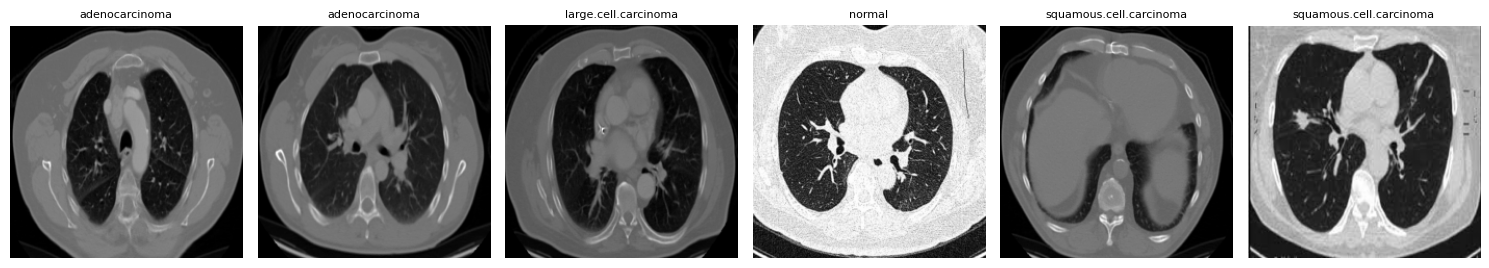

task: multiclass | loss: CrossEntropyLoss


In [6]:
import matplotlib.pyplot as plt
# a few samples
fig, ax = plt.subplots(1, 6, figsize=(15, 2.8))
for a, i in zip(ax, np.linspace(0, len(Xtr) - 1, 6).astype(int)):
    a.imshow(Xtr[i], cmap="gray"); a.axis("off"); a.set_title(str(Ytr[i]) if TASK == "multilabel" else CLASS_NAMES[int(Ytr[i])], fontsize=8)
plt.tight_layout(); plt.show()

set_seed(SEED)
train_loader = ArrayLoader(Xtr, Ytr, BATCH_SIZE, TASK, shuffle=True, augment=USE_AUGMENTATION, drop_last=True)
val_loader   = ArrayLoader(Xva, Yva, BATCH_SIZE * 2, TASK)
test_loader  = ArrayLoader(Xte, Yte, BATCH_SIZE * 2, TASK)

if TASK == "multilabel":
    pos = Ytr.sum(0); neg = len(Ytr) - pos
    pw = torch.tensor(neg / np.maximum(pos, 1), dtype=torch.float32).to(DEVICE) if USE_CLASS_WEIGHTS else None
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
else:
    cnt = np.bincount(Ytr, minlength=NUM_CLASSES)
    cw = torch.tensor(cnt.sum() / (NUM_CLASSES * np.maximum(cnt, 1)), dtype=torch.float32).to(DEVICE) if USE_CLASS_WEIGHTS else None
    criterion = nn.CrossEntropyLoss(weight=cw)
print("task:", TASK, "| loss:", type(criterion).__name__)

## 6. Run the ablation experiments

Each experiment trains one model and saves its checkpoint and results to the output folder, so **if the session stops, re-running this cell skips the finished experiments** and carries on. Test metrics are logged each epoch only for the curves.

In [7]:
os.makedirs(OUT_DIR, exist_ok=True)

def build_model(cfg):
    return MMF(NUM_CLASSES, cfg, weights_path=WEIGHTS_PATH, vit1_dim=VIT1_DIM, vit2_dim=VIT2_DIM,
               cnn_dim=CNN_DIM, pretrained=PRETRAINED).to(DEVICE)

def run_experiment(name, cfg):
    ckpt, resf = f"{OUT_DIR}/{name}.pt", f"{OUT_DIR}/{name}.json"
    if os.path.exists(resf) and os.path.exists(ckpt):                      # resume: skip finished experiments
        print(f"[{name}] already finished, loading saved results"); return json.load(open(resf))
    print(f"\n{'='*100}\n[{name}]  {cfg}\n{'='*100}")
    set_seed(SEED)
    model = build_model(cfg)
    total, train, madds = complexity(model)
    print(f"params {total/1e6:.2f} M (trainable {train/1e6:.2f} M) | fwd {madds/1e6:.0f} MMAdds/img | "
          f"ViT-1 tokens {model.vit1.num_tokens} | ViT-2 tokens {model.vit2.num_tokens} | fusion dims {model.dims}")
    hist, best_ep = fit(model, train_loader, val_loader, test_loader, criterion, TASK, EPOCHS, LR, WEIGHT_DECAY, SELECT_BY, ckpt)
    res = dict(name=name, cfg=cfg, best_epoch=best_ep, history=hist, params=total, trainable=train, madds=madds,
               vit1_tokens=model.vit1.num_tokens, vit2_tokens=model.vit2.num_tokens, dims=model.dims)
    use_amp = DEVICE.type == "cuda"
    for split, loader in [("val", val_loader), ("test", test_loader)]:
        l, y, p, pr = predict(model, loader, criterion, TASK, use_amp)
        res[split] = dict(loss=l, auc=auc_score(y, pr, TASK), **metrics(y, p, TASK))
        res[f"{split}_y"], res[f"{split}_pred"] = y.tolist(), p.tolist()
    json.dump(res, open(resf, "w"))
    del model; torch.cuda.empty_cache() if DEVICE.type == "cuda" else None
    return res

RESULTS = {}
for name in RUN:
    RESULTS[name] = run_experiment(name, EXPERIMENTS[name])
print("\nall experiments finished:", list(RESULTS))


[E4_vit2_patch16]  {'vit1_src': 'dec28', 'vit1_patch': 7, 'vit1_stride': 7, 'vit2_src': 'adapter56', 'vit2_patch': 16, 'vit2_stride': 8, 'use_2maxmin': False, 'multiplier': 1.0}
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 125MB/s]


params 3.12 M (trainable 2.99 M) | fwd 338 MMAdds/img | ViT-1 tokens 16 | ViT-2 tokens 36 | fusion dims {'cnn': 128, 'vit1': 48, 'vit2': 48, 'fusion': 224}
Ep 01/25 |     6s | loss tr 0.7915 val 1.1235 test 1.2059 | F1 tr 0.660 val 0.458 test 0.255  *best* | ETA this run ~3 min
Ep 02/25 |     1s | loss tr 0.1673 val 0.6869 test 1.1633 | F1 tr 0.965 val 0.728 test 0.496  *best*
Ep 03/25 |     1s | loss tr 0.0480 val 0.4471 test 0.6783 | F1 tr 0.993 val 0.851 test 0.753  *best*
Ep 04/25 |     1s | loss tr 0.0325 val 0.3985 test 0.4682 | F1 tr 0.995 val 0.853 test 0.836  *best*
Ep 05/25 |     1s | loss tr 0.0193 val 0.3983 test 0.4461 | F1 tr 0.998 val 0.868 test 0.846  *best*
Ep 06/25 |     1s | loss tr 0.0141 val 0.4371 test 0.4563 | F1 tr 0.998 val 0.868 test 0.852
Ep 07/25 |     1s | loss tr 0.0147 val 0.4272 test 0.4485 | F1 tr 0.997 val 0.855 test 0.855
Ep 08/25 |     1s | loss tr 0.0106 val 0.4064 test 0.4535 | F1 tr 0.998 val 0.868 test 0.846
Ep 09/25 |     1s | loss tr 0.0106 val

## 7. Results: summary, curves, confusion matrices

,ViT-1 input,ViT-1 patch/stride,ViT-1 tokens,ViT-2 input,ViT-2 patch/stride,ViT-2 tokens,2maxmin,params (M),trainable (M),MAdds/img (M),best ep,val loss,test loss,test acc,test precision,test recall,test F1,test AUC
experiment,,,,,,,,,,,,,,,,,,
E4_vit2_patch16,dec28 (32x28^2),7/7,16,adapter56 (16x56^2),16/8,36,False,3.1159,2.9851,337.7477,15,0.3943,0.4641,0.8508,0.8735,0.8508,0.8526,0.9755


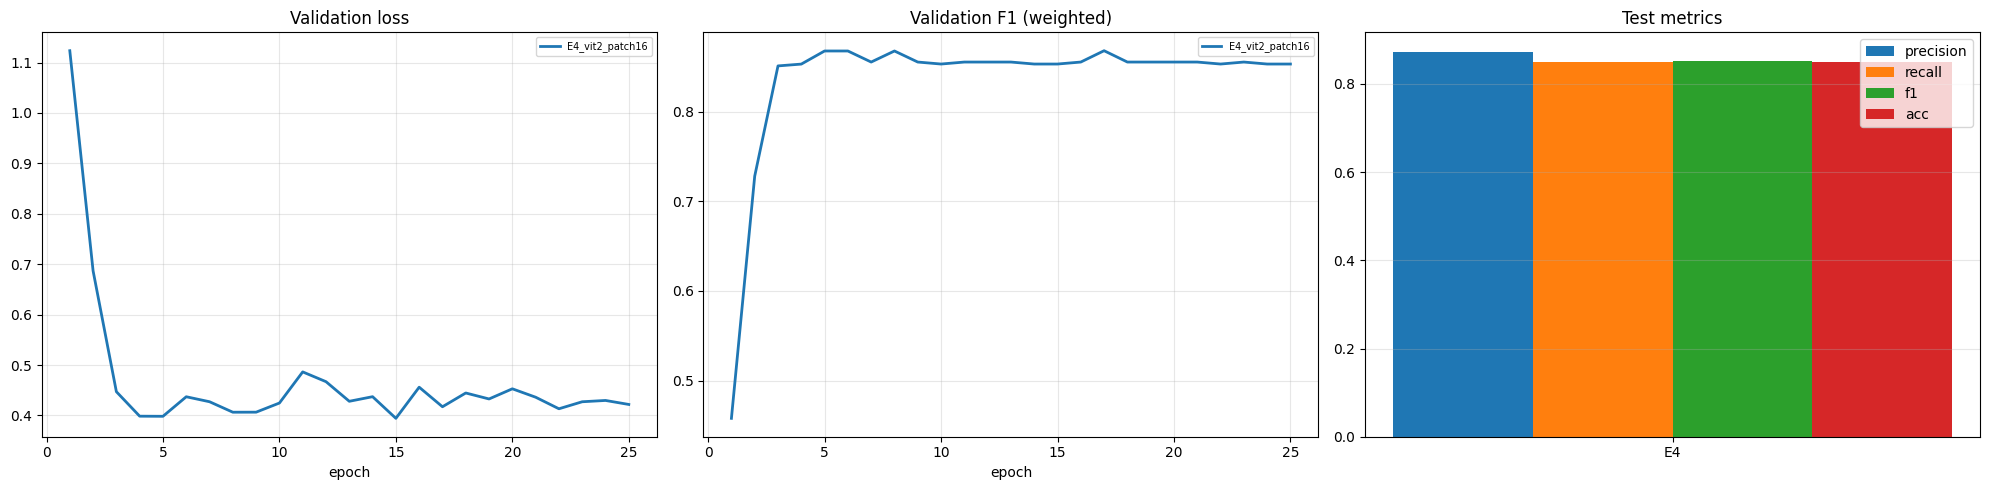

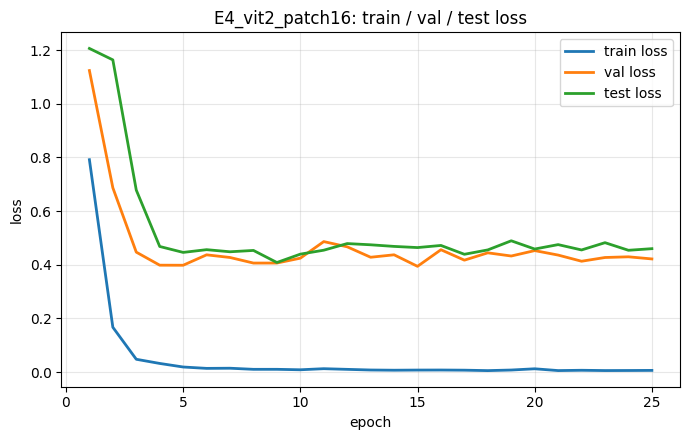

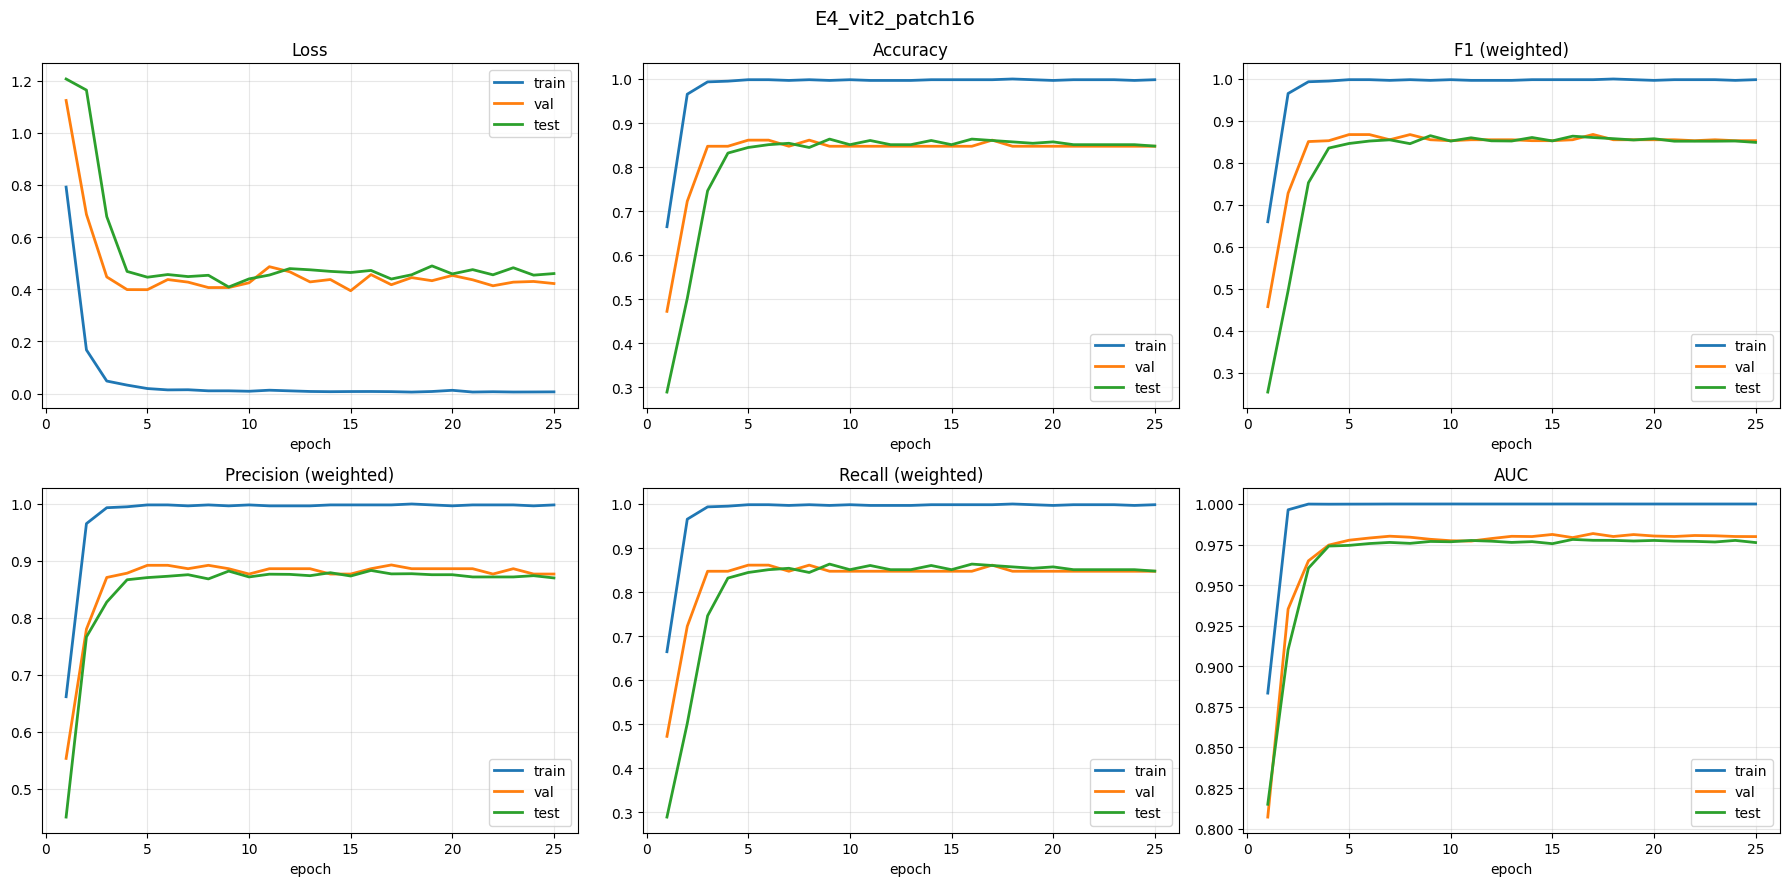

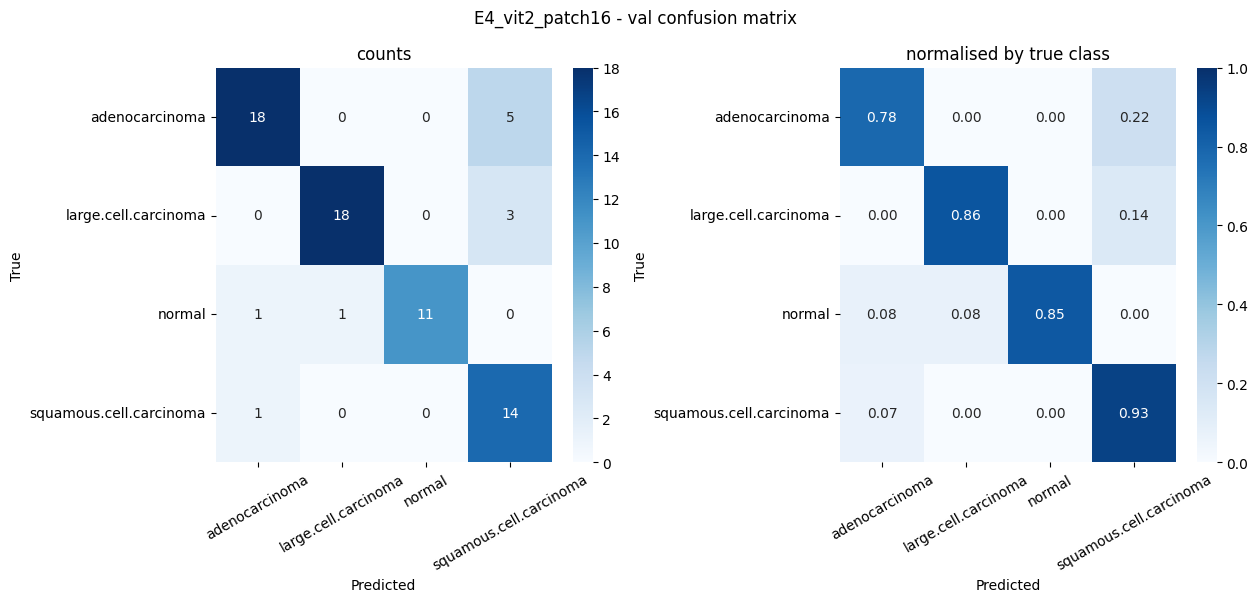

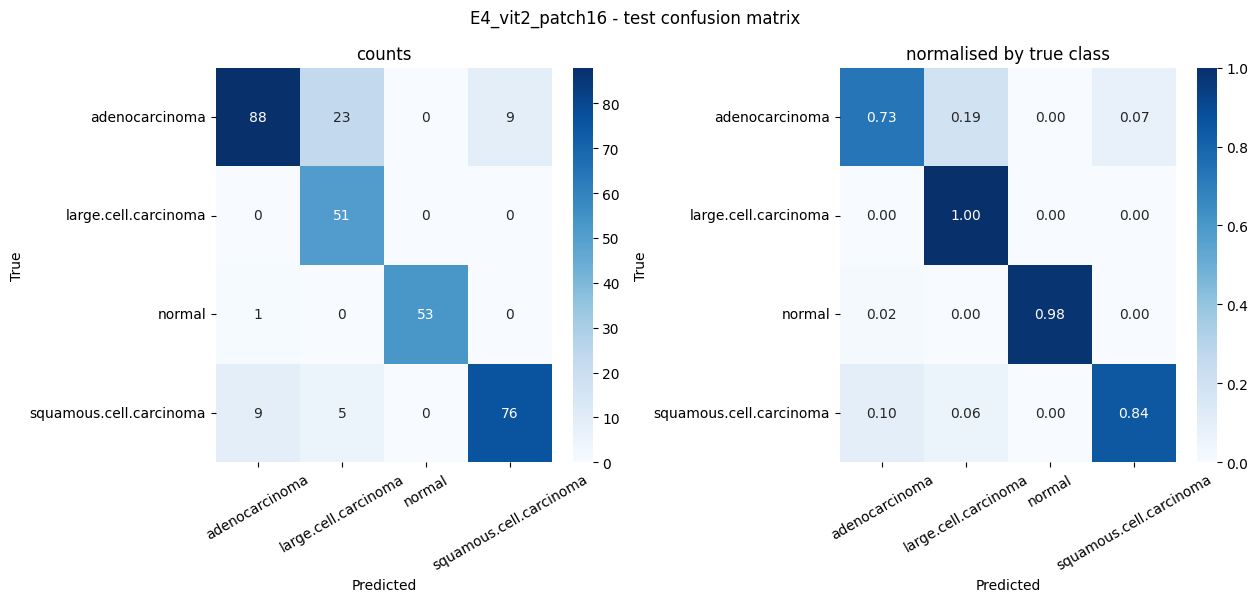

--- E4_vit2_patch16: test classification report ---
                         precision    recall  f1-score   support

         adenocarcinoma     0.8980    0.7333    0.8073       120
   large.cell.carcinoma     0.6456    1.0000    0.7846        51
                 normal     1.0000    0.9815    0.9907        54
squamous.cell.carcinoma     0.8941    0.8444    0.8686        90

               accuracy                         0.8508       315
              macro avg     0.8594    0.8898    0.8628       315
           weighted avg     0.8735    0.8508    0.8526       315



In [8]:
def summary_table():
    rows = []
    for n, r in RESULTS.items():
        c = r["cfg"]
        rows.append({"experiment": n,
            "ViT-1 input": f'{c["vit1_src"]} ({TAPS[c["vit1_src"]][0]}x{TAPS[c["vit1_src"]][1]}^2)',
            "ViT-1 patch/stride": f'{c["vit1_patch"]}/{c["vit1_stride"]}', "ViT-1 tokens": r["vit1_tokens"],
            "ViT-2 input": f'{c["vit2_src"]} ({TAPS[c["vit2_src"]][0]}x{TAPS[c["vit2_src"]][1]}^2)',
            "ViT-2 patch/stride": f'{c["vit2_patch"]}/{c["vit2_stride"]}', "ViT-2 tokens": r["vit2_tokens"],
            "2maxmin": c["use_2maxmin"], "params (M)": r["params"] / 1e6, "trainable (M)": r["trainable"] / 1e6,
            "MAdds/img (M)": r["madds"] / 1e6, "best ep": r["best_epoch"],
            "val loss": r["val"]["loss"], "test loss": r["test"]["loss"], "test acc": r["test"]["acc"],
            "test precision": r["test"]["precision"], "test recall": r["test"]["recall"],
            "test F1": r["test"]["f1"], "test AUC": r["test"]["auc"]})
    return pd.DataFrame(rows).set_index("experiment")

def plot_history(name):
    h = RESULTS[name]["history"]; ep = range(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(2, 3, figsize=(18, 9)); ax = ax.ravel()
    for a, (k, t) in zip(ax, [("loss", "Loss"), ("acc", "Accuracy"), ("f1", f"F1 ({AVG[TASK]})"),
                              ("precision", f"Precision ({AVG[TASK]})"), ("recall", f"Recall ({AVG[TASK]})"), ("auc", "AUC")]):
        for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
            a.plot(ep, h[f"{s}_{k}"], label=s, color=c, lw=2)
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
    fig.suptitle(name, fontsize=14); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}_curves.png", dpi=130); plt.show()

def plot_loss_only(name):
    h = RESULTS[name]["history"]; ep = range(1, len(h["train_loss"]) + 1)
    plt.figure(figsize=(7, 4.5))
    for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:green")]:
        plt.plot(ep, h[f"{s}_loss"], label=f"{s} loss", color=c, lw=2)
    plt.title(f"{name}: train / val / test loss"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.grid(alpha=.3); plt.legend()
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}_loss.png", dpi=130); plt.show()

def plot_confusions(name, split="test"):
    r = RESULTS[name]; y, p = np.array(r[f"{split}_y"]), np.array(r[f"{split}_pred"])
    if TASK == "multilabel":
        fig, ax = plt.subplots(1, len(CLASS_NAMES), figsize=(5 * len(CLASS_NAMES), 4.3)); ax = np.atleast_1d(ax)
        for i, nme in enumerate(CLASS_NAMES):
            sns.heatmap(confusion_matrix(y[:, i], p[:, i], labels=[0, 1]), annot=True, fmt="d", cmap="Blues", ax=ax[i],
                        xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"]); ax[i].set_title(nme)
            ax[i].set_xlabel("Predicted"); ax[i].set_ylabel("Actual")
    else:
        cm = confusion_matrix(y, p, labels=range(len(CLASS_NAMES))); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
        n = len(CLASS_NAMES); fig, ax = plt.subplots(1, 2, figsize=(max(11, 3.2 * n), max(4.5, 0.9 * n + 2.5)))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[0]); ax[0].set_title("counts")
        sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], vmin=0, vmax=1)
        ax[1].set_title("normalised by true class")
        for a in ax: a.set_xlabel("Predicted"); a.set_ylabel("True"); a.tick_params(axis="x", rotation=30)
    fig.suptitle(f"{name} - {split} confusion matrix"); plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{name}_confusion_{split}.png", dpi=130); plt.show()

def print_report(name):
    r = RESULTS[name]; y, p = np.array(r["test_y"]), np.array(r["test_pred"])
    print(f"--- {name}: test classification report ---")
    if TASK == "multilabel":
        for i, nme in enumerate(CLASS_NAMES):
            print(nme); print(classification_report(y[:, i], p[:, i], target_names=["Negative", "Positive"], digits=4, zero_division=0))
    else:
        print(classification_report(y, p, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES, digits=4, zero_division=0))

def plot_comparison():
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    for n, r in RESULTS.items():
        h = r["history"]; ep = range(1, len(h["val_loss"]) + 1)
        ax[0].plot(ep, h["val_loss"], label=n, lw=2); ax[1].plot(ep, h["val_f1"], label=n, lw=2)
    ax[0].set_title("Validation loss"); ax[1].set_title(f"Validation F1 ({AVG[TASK]})")
    for a in ax[:2]: a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend(fontsize=7)
    names = list(RESULTS); x = np.arange(len(names)); w = 0.2
    for i, k in enumerate(["precision", "recall", "f1", "acc"]):
        ax[2].bar(x + (i - 1.5) * w, [RESULTS[n]["test"][k] for n in names], w, label=k)
    ax[2].set_xticks(x); ax[2].set_xticklabels([n.split("_")[0] for n in names]); ax[2].set_title("Test metrics"); ax[2].legend(); ax[2].grid(alpha=.3, axis="y")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparison.png", dpi=130); plt.show()

df = summary_table()
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
display(df.round(4)); df.to_csv(f"{OUT_DIR}/ablation_summary.csv")
plot_comparison()
for n in RESULTS:
    plot_loss_only(n); plot_history(n); plot_confusions(n, "val"); plot_confusions(n, "test"); print_report(n)

## 8. 2maxmin + x1.1 multiplier: images

(a) The operation `2*maxpool - minpool` (kernel 2, stride 1) followed by `x1.1`, applied directly to X-rays. (b) The same operation applied to the 28x28x32 decoder features, i.e. the tensor ViT-1 receives in the original model.

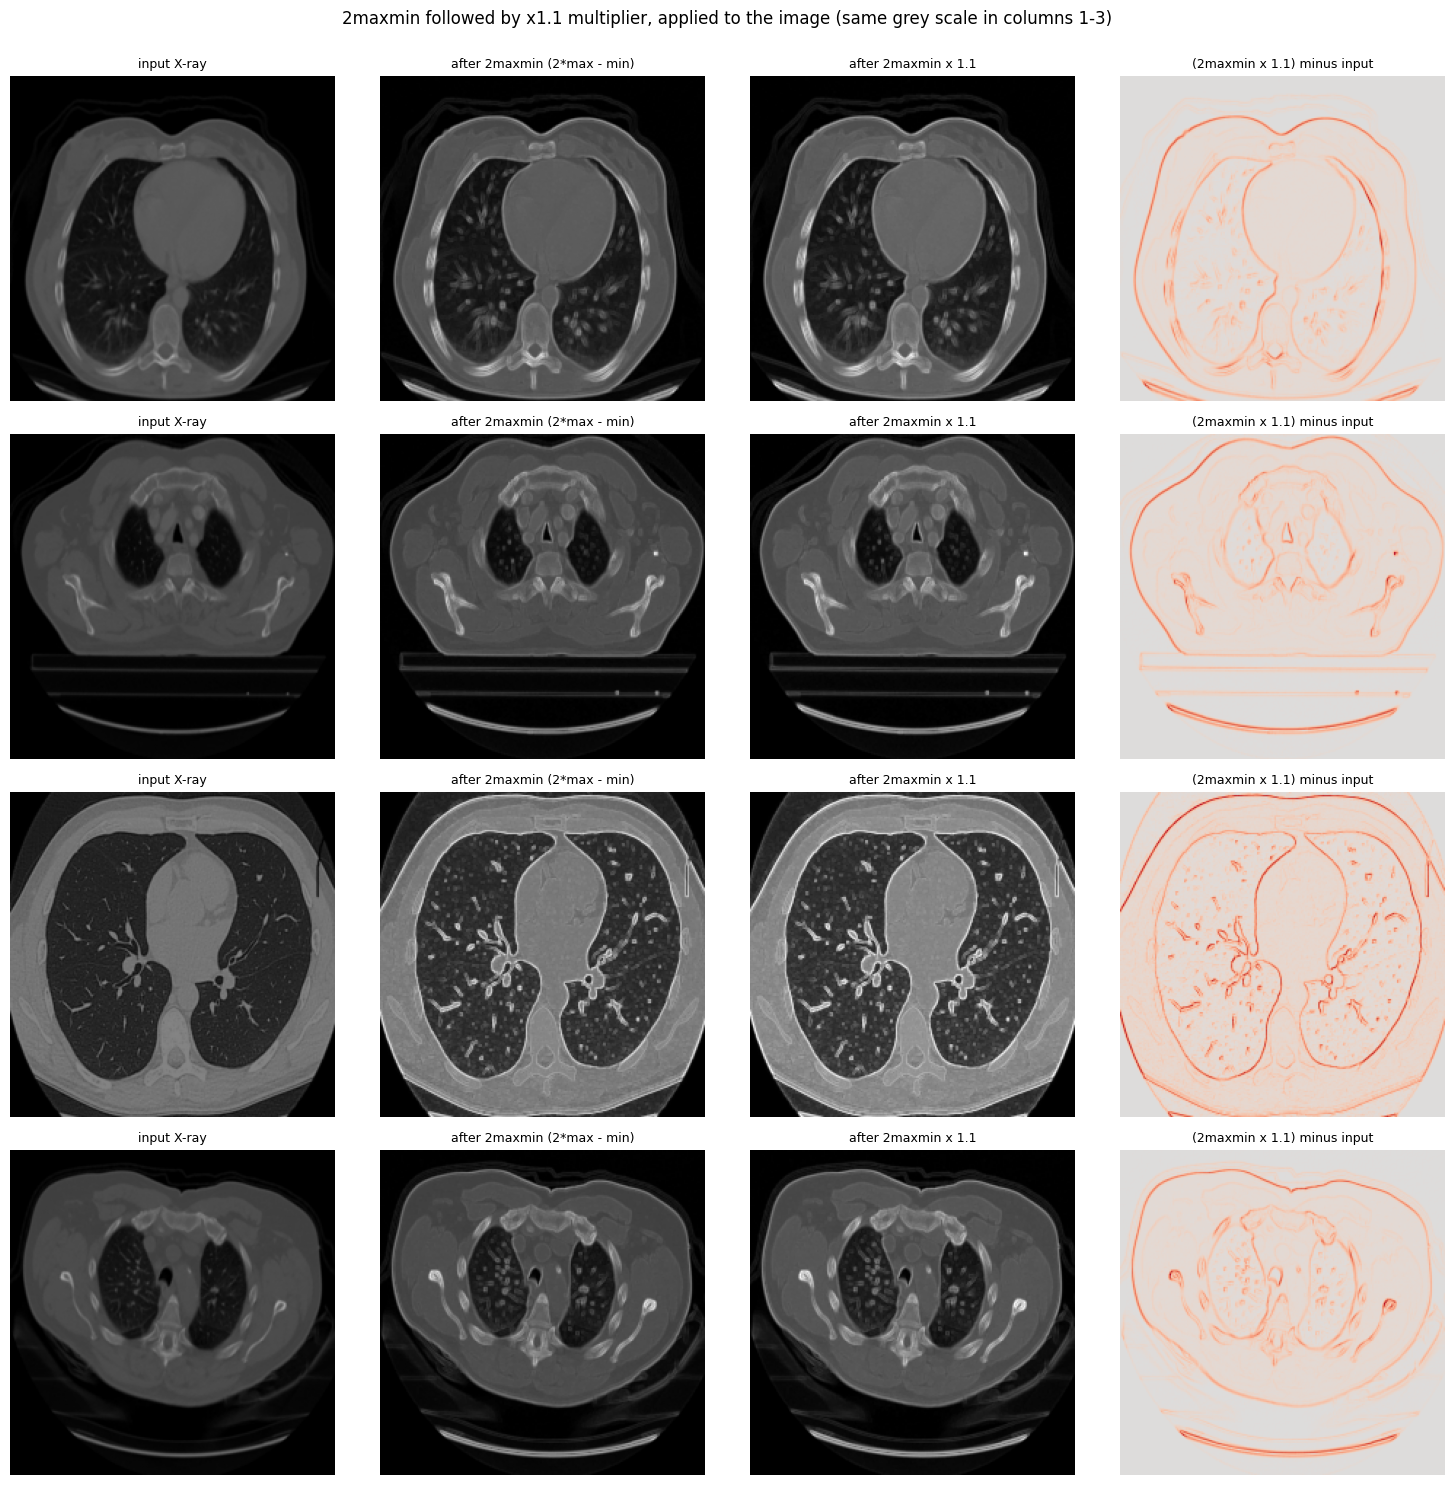

using trained weights: /kaggle/working/ablation_lungct_E4/E4_vit2_patch16.pt


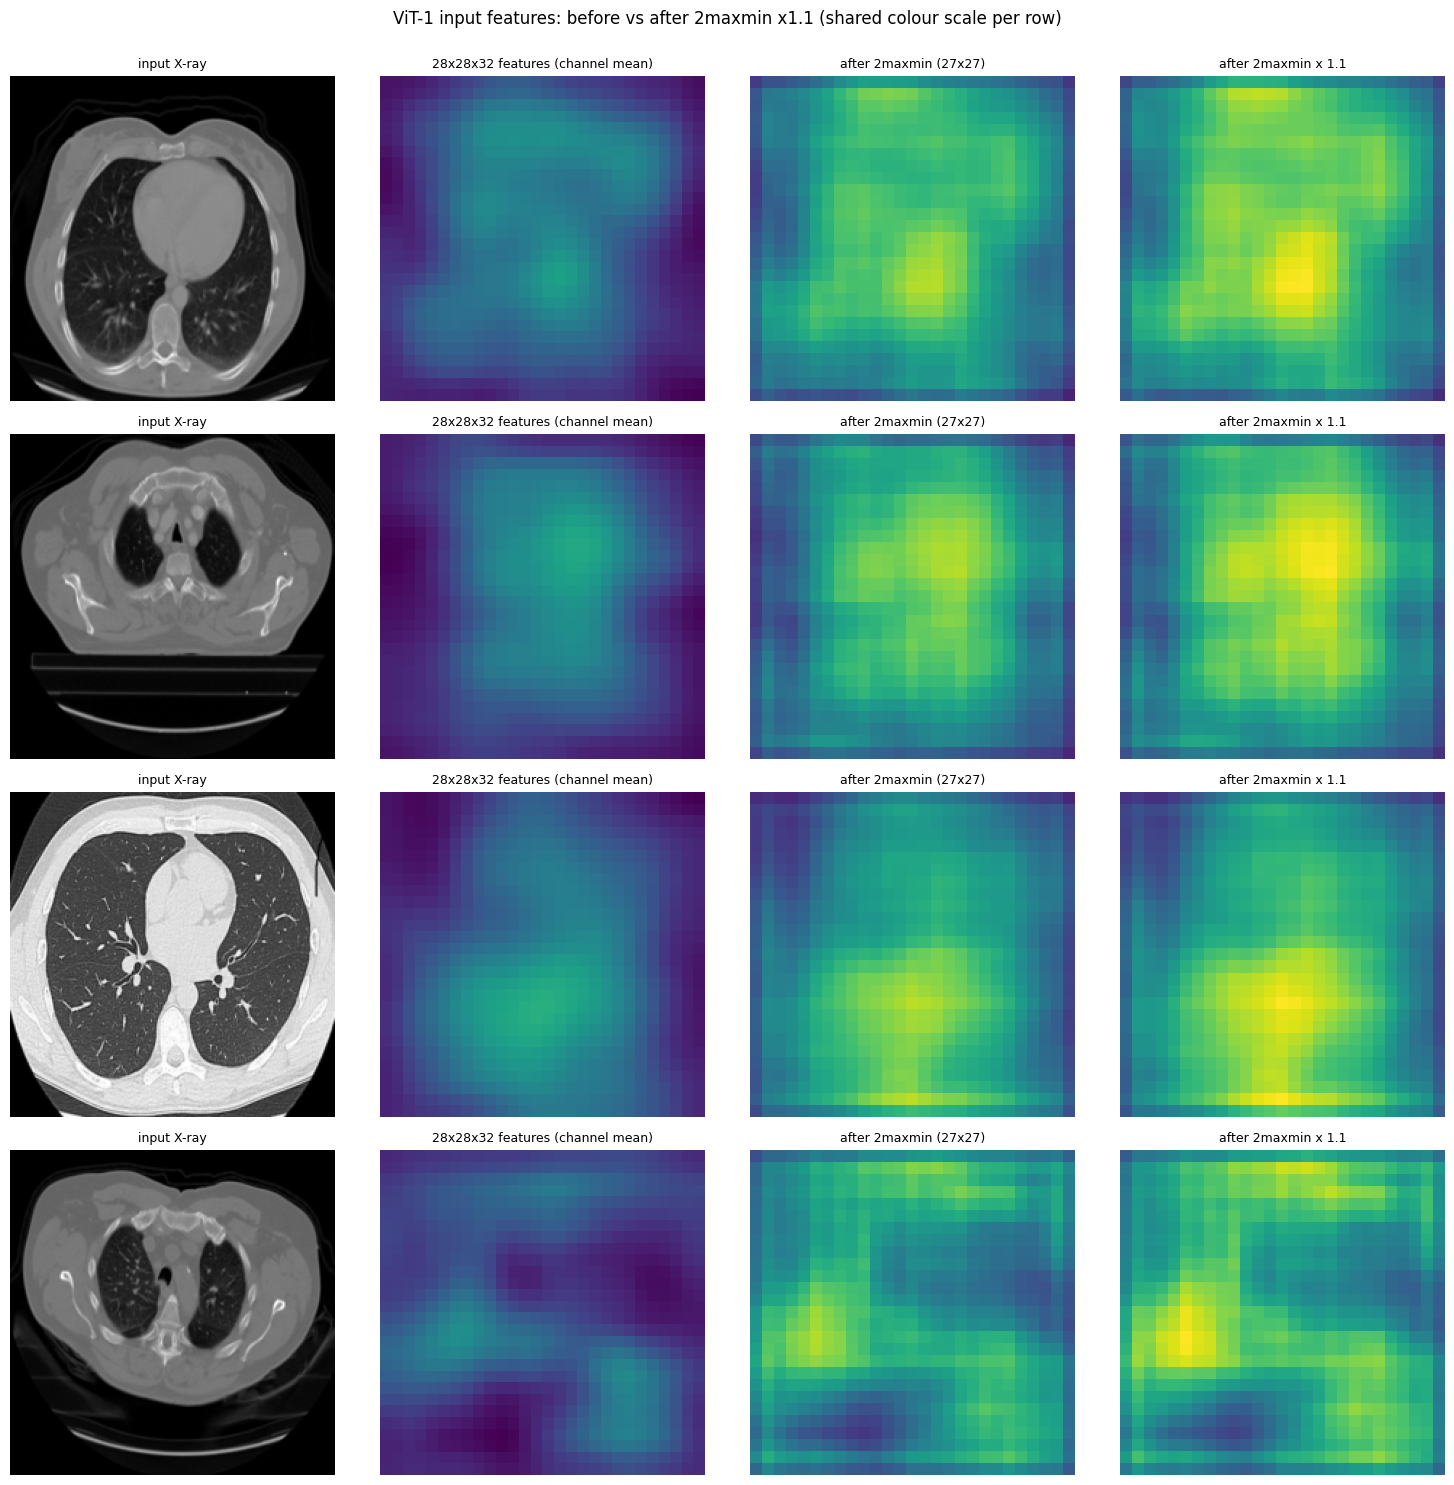

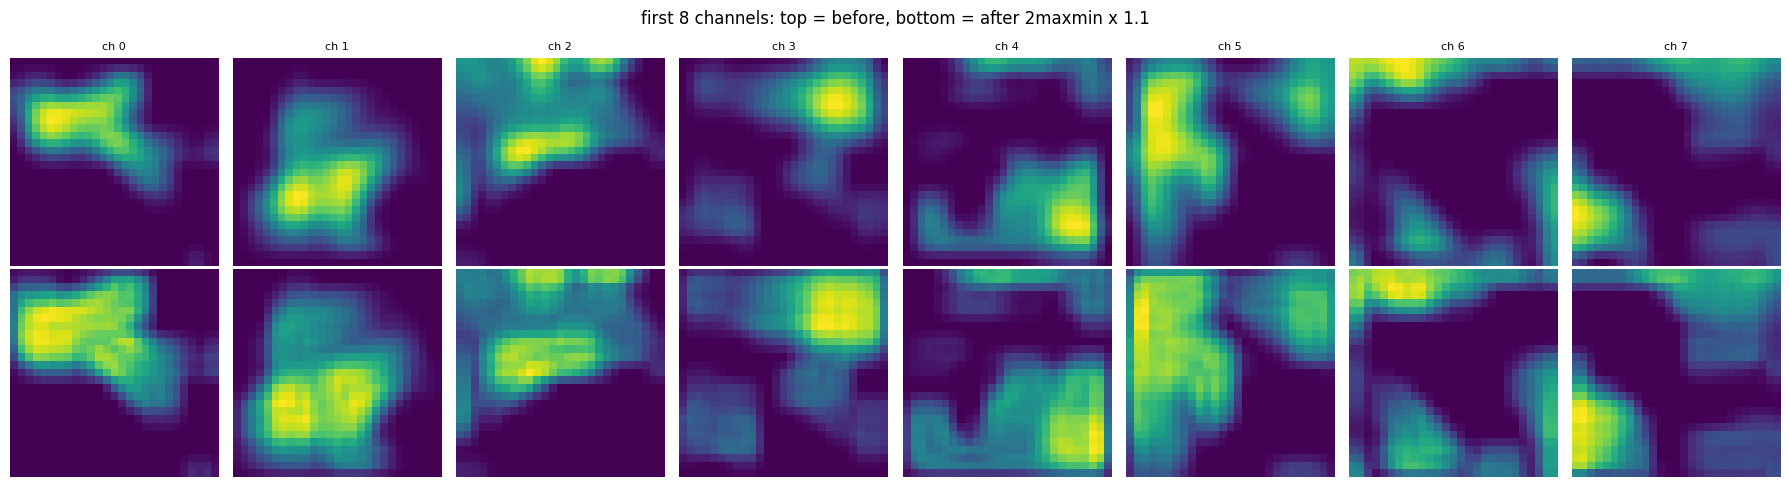

In [9]:
# ---------- 2maxmin + multiplier visualisation (this is the ONLY place 2maxmin is used) ----------
VIS_EXPERIMENT = "E4_vit2_patch16"   # trained model whose decoder features are visualised (falls back to untrained decoder)
VIS_MULT = 1.1
N_VIS = 4
pool = TwoMaxMinusMinPool2d(2, 1)
idx = np.linspace(0, len(Xte) - 1, N_VIS).astype(int)

# (a) the operation applied directly to the X-ray
fig, ax = plt.subplots(N_VIS, 4, figsize=(15, 3.7 * N_VIS))
for r, i in enumerate(idx):
    img = torch.from_numpy(Xte[i]).float().div(255)[None, None]
    pooled = pool(img); scaled = pooled * VIS_MULT
    orig = img[:, :, :pooled.shape[2], :pooled.shape[3]]
    lo, hi = min(orig.min(), pooled.min(), scaled.min()).item(), max(orig.max(), pooled.max(), scaled.max()).item()
    diff = (scaled - orig)[0, 0].numpy(); m = np.abs(diff).max() + 1e-8
    for c, (im, t, kw) in enumerate([(orig, "input X-ray", dict(cmap="gray", vmin=lo, vmax=hi)),
                                     (pooled, "after 2maxmin (2*max - min)", dict(cmap="gray", vmin=lo, vmax=hi)),
                                     (scaled, f"after 2maxmin x {VIS_MULT}", dict(cmap="gray", vmin=lo, vmax=hi)),
                                     (torch.from_numpy(diff)[None, None], f"(2maxmin x {VIS_MULT}) minus input", dict(cmap="coolwarm", vmin=-m, vmax=m))]):
        ax[r, c].imshow(im[0, 0], **kw); ax[r, c].set_title(t, fontsize=9); ax[r, c].axis("off")
fig.suptitle(f"2maxmin followed by x{VIS_MULT} multiplier, applied to the image (same grey scale in columns 1-3)", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vis_2maxmin_images.png", dpi=130); plt.show()

# (b) the operation applied to the 28x28x32 decoder features that ViT-1 receives in the original model
vis_cfg = EXPERIMENTS.get(VIS_EXPERIMENT, BASE); vis_model = build_model(vis_cfg)
ck = f"{OUT_DIR}/{VIS_EXPERIMENT}.pt"
if os.path.exists(ck):
    vis_model.load_state_dict(torch.load(ck, map_location=DEVICE)); print("using trained weights:", ck)
else:
    print("WARNING: no trained checkpoint found, showing features of an untrained decoder")
vis_model.eval()
fig, ax = plt.subplots(N_VIS, 4, figsize=(15, 3.7 * N_VIS))
chan_figs = []
for r, i in enumerate(idx):
    x01 = torch.from_numpy(Xte[i]).float().div(255)[None, None].to(DEVICE)
    with torch.no_grad():
        f = vis_model.extract(prep(x01))["dec28"]                       # 1x32x28x28
        fp = pool(f); fs = fp * VIS_MULT
    maps = [f.mean(1)[0].cpu(), fp.mean(1)[0].cpu(), fs.mean(1)[0].cpu()]
    lo, hi = min(m.min() for m in maps).item(), max(m.max() for m in maps).item()
    ax[r, 0].imshow(x01[0, 0].cpu(), cmap="gray"); ax[r, 0].set_title("input X-ray", fontsize=9)
    for c, (m, t) in enumerate(zip(maps, ["28x28x32 features (channel mean)", "after 2maxmin (27x27)", f"after 2maxmin x {VIS_MULT}"])):
        ax[r, c + 1].imshow(m, cmap="viridis", vmin=lo, vmax=hi); ax[r, c + 1].set_title(t, fontsize=9)
    for a in ax[r]: a.axis("off")
    chan_figs.append((f[0].cpu(), fs[0].cpu()))
fig.suptitle(f"ViT-1 input features: before vs after 2maxmin x{VIS_MULT} (shared colour scale per row)", y=1.0)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vis_2maxmin_features.png", dpi=130); plt.show()

# individual channels, first test image: row 1 = original features, row 2 = after 2maxmin x multiplier
f0, fs0 = chan_figs[0]
fig, ax = plt.subplots(2, 8, figsize=(18, 5))
for c in range(8):
    ax[0, c].imshow(f0[c], cmap="viridis"); ax[0, c].set_title(f"ch {c}", fontsize=8)
    ax[1, c].imshow(fs0[c], cmap="viridis"); ax[0, c].axis("off"); ax[1, c].axis("off")
ax[0, 0].set_ylabel("before"); fig.suptitle(f"first 8 channels: top = before, bottom = after 2maxmin x {VIS_MULT}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/vis_2maxmin_channels.png", dpi=130); plt.show()

## Notes
- Plain training by default (no augmentation, no class weights); switches are in the config cell.
- The CNN branch is the 1x1 + 3x3 conv head (128 wide, as in Fig. 1) on the concatenated MobileNetV2 features (160 ch + 1280 ch), followed by global average pooling. Fusion widths are CNN : ViT-1 : ViT-2 = 128 : 48 : 48. Change `CNN_DIM` / `VIT1_DIM` / `VIT2_DIM` in the config to try other ratios.
- Frozen layers: the first half of MobileNetV2 has `requires_grad=False`, as in the reference (its BatchNorm statistics still update in train mode, again as in the reference).
- Time: 1 experiment x `EPOCHS` epochs. Lower `EPOCHS` (or `SUBSET_FRACTION`) if the session limit is a problem; finished experiments are kept.
- Results: `<OUT_DIR>/ablation_summary.csv`, per-experiment PNGs and JSON.
- 4-class CT task (adenocarcinoma, large cell carcinoma, squamous cell carcinoma, normal). Multiclass metrics are **weighted** averages; the test set is small, so read the per-class report and not only accuracy.
- CT slices are converted to 224x224 grayscale (replicated to 3 channels for MobileNetV2).